# Model selection and one-time evaluation

Compare dated validation, candidate models and archived test evidence.

In [1]:
import sys
from pathlib import Path

HERE = Path.cwd().resolve()
NB = HERE if (HERE / 'mandi_notes.py').is_file() else HERE / 'Notebook'
sys.path.insert(0, str(NB))
from mandi_notes import *

,period,first_target_sunday,last_target_sunday
0,train,2002-01-06,2018-12-30
1,val_2019,2019-01-06,2019-12-29
2,val_2020,2020-01-05,2020-12-27
3,test,2021-01-03,2022-12-25
4,holdout_no_weather,2023-01-01,last input date


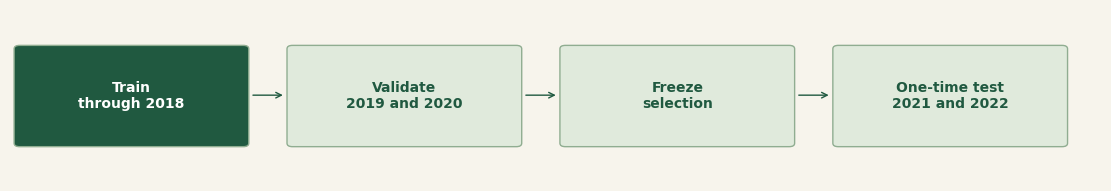

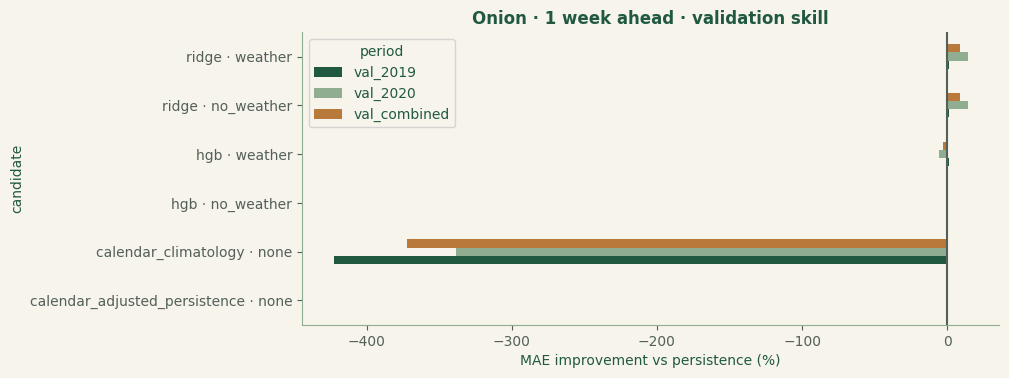

,candidate,period,mae,rmse,mape_pct
24,hgb · weather,val_2019,198.23,421.70,8.75
36,ridge · no_weather,val_2019,198.67,440.14,8.72
42,ridge · weather,val_2019,198.70,439.62,8.73
18,hgb · no_weather,val_2019,199.15,426.76,8.74
0,calendar_adjusted_persistence · none,val_2019,200.98,453.18,8.80
12,calendar_climatology · none,val_2019,1048.71,1705.50,46.46
43,ridge · weather,val_2020,280.87,575.21,10.76
37,ridge · no_weather,val_2020,281.11,576.52,10.76
1,calendar_adjusted_persistence · none,val_2020,327.78,611.00,12.14
19,hgb · no_weather,val_2020,330.35,557.68,12.77


,crop,horizon_weeks,proposed,skill_2019,skill_2020,skill_combined,candidates_beating_persistence_both_years
0,Onion,1,ridge (no_weather),0.009831,0.140467,0.088467,2


interactive(children=(Dropdown(description='Crop', options=('Onion', 'Potato', 'Wheat'), value='Onion'), Dropd…

In [2]:
splits = pd.read_csv(PH8 / "split_definition.csv")
display(splits[["period", "first_target_sunday", "last_target_sunday"]])
diagram(["Train\nthrough 2018", "Validate\n2019 and 2020", "Freeze\nselection", "One-time test\n2021 and 2022"])
validation = pd.read_csv(PH8 / "model_validation_metrics.csv")
selection = pd.read_csv(PH8 / "model_selection_validation.csv")

def compare(crop, horizon):
    rows = validation[(validation.crop == crop) & (validation.horizon_weeks == horizon)
                      & (validation.experiment == "primary") & (validation.subset == "all")].copy()
    rows["candidate"] = rows.model + " · " + rows.config.fillna("none")
    scores = rows.pivot_table(index="candidate", columns="period", values="skill_mae_vs_persistence") * 100
    if not scores.empty:
        ax = scores.plot.barh(title=f"{crop} · {horizon} week ahead · validation skill", xlabel="MAE improvement vs persistence (%)")
        ax.axvline(0, color=GRAY)
        plt.show()
    display(rows[["candidate", "period", "mae", "rmse", "mape_pct"]].sort_values(["period", "mae"]).round(2).head(10))
    display(selection.query("crop == @crop and horizon_weeks == @horizon"))
controls(compare, crop=CROPS, horizon=[1, 2, 4])

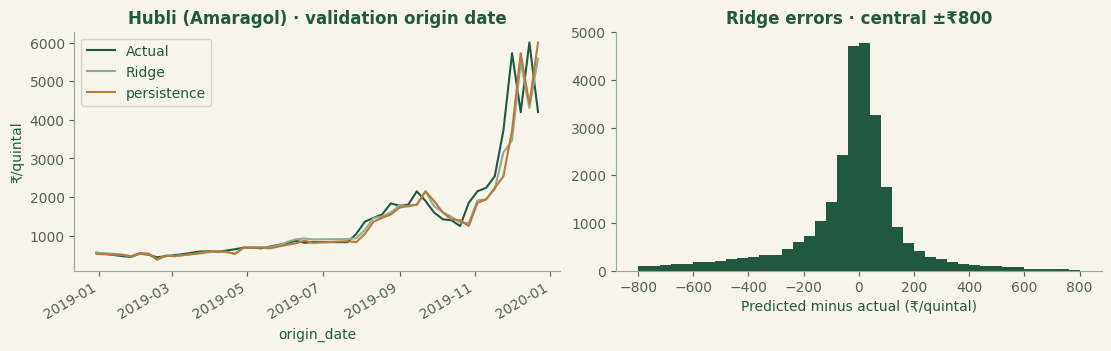

,crop,horizon_weeks,approach,period,mae,persistence_mae
0,Onion,1,hgb_conservative,test_2021,239.05,227.31
1,Onion,1,hgb_conservative,test_2022,141.51,146.35
2,Onion,1,hgb_conservative,test_combined,187.13,184.22
3,Onion,2,persistence,test_2021,355.26,355.26
4,Onion,2,persistence,test_2022,213.57,213.57
5,Onion,2,persistence,test_combined,279.73,279.73
6,Onion,4,persistence,test_2021,531.66,531.66
7,Onion,4,persistence,test_2022,314.47,314.47
8,Onion,4,persistence,test_combined,415.77,415.77
9,Potato,1,persistence,test_2021,94.85,94.85


,Commodity,mae,mape_pct,state_mae_ci95_lo,state_mae_ci95_hi
0,Onion,231.32,7.62,219.43,249.32
1,Potato,32.03,3.52,20.87,55.22
2,Wheat,40.75,1.53,27.34,60.43


In [3]:
points = pd.read_parquet(PH8 / "validation_predictions.parquet",
    columns=["market","origin_date","y","yhat","persistence"],
    filters=[("crop","==","Onion"),("horizon_weeks","==",1),("model","==","ridge"),
             ("config","==","no_weather"),("period","==","val_2019")])
if not points.empty:
    market = points.market.value_counts().index[0]
    track = points[points.market == market].groupby("origin_date")[["y","yhat","persistence"]].median().sort_index()
    fig, axes = plt.subplots(1,2, figsize=(11,3.4),layout="constrained")
    track.rename(columns={"y":"Actual","yhat":"Ridge"}).plot(ax=axes[0], title=market+" · validation origin date", ylabel="₹/quintal")
    axes[1].hist(points.yhat - points.y, bins=40, range=(-800,800))
    axes[1].set(title="Ridge errors · central ±₹800", xlabel="Predicted minus actual (₹/quintal)")
    plt.show()

test = pd.read_csv(PH8 / "test_results.csv")
display(test[["crop","horizon_weeks","approach","period","mae","persistence_mae"]].round(2).head(10))
d52 = pd.read_csv(CANDIDATE / "exp_candidate_v1/persistence_test_d52/run/by_crop.csv")
display(d52.query("design == 'faq_only' and horizon == 1")[["Commodity","mae","mape_pct","state_mae_ci95_lo","state_mae_ci95_hi"]].round(2))

The error histogram and time series use saved validation predictions. The test tables read saved aggregate metrics only. D-52 tested persistence on the later candidate dataset from July to October 2026. The separately archived exp-v3 validation found trailing median, EWMA and drift weaker than persistence across crop and horizon cells.

**Takeaway** · Validation gains sometimes reversed on later data. Persistence remains the operational price baseline.

**Next** · Inspect a published forecast and its issue date in Notebook 09.